# 03. Machine Learning Model Training — ThyroidSense

**Project:** ThyroidSense: Thyroid Disease Detection Using Machine Learning  
**Author:** Venkatesh Devarakonda  
**Curriculum:** B.Tech CSE (AI & ML) — Semester 2-1 Academic Project  

---

## 1. Objective
Train six traditional supervised classification models on the standardized thyroid dataset:
1. **Logistic Regression** (Linear Multinomial Baseline)
2. **Decision Tree Classifier** (Interpretable Tree)
3. **Random Forest Classifier** (Ensemble Bagging)
4. **K-Nearest Neighbors (KNN)** (Instance-based, k=3 from original project)
5. **Support Vector Machine (SVC)** (RBF Kernel, probability=True from original project)
6. **Gaussian Naive Bayes** (Probabilistic Baseline)


In [1]:
import os
import sys
import time
import pandas as pd
import numpy as np

# Add project root to sys.path
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))

from src.data_preprocessing import preprocess_pipeline
from src.model_training import get_model_definitions, train_single_model, train_all_models

print("Training modules loaded successfully!")


Training modules loaded successfully!


## 2. Load and Prepare Preprocessed Data

In [2]:
data_path = os.path.join("..", "data", "processed", "thyroid_processed.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "processed", "thyroid_processed.csv")

bundle = preprocess_pipeline(filepath=data_path, save_scaler=True)
X_train = bundle["X_train_scaled"]
y_train = bundle["y_train"].values
X_test = bundle["X_test_scaled"]
y_test = bundle["y_test"].values
feature_names = bundle["feature_names"]

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")


X_train shape: (16000, 14) | y_train shape: (16000,)
X_test shape:  (4000, 14)  | y_test shape:  (4000,)


## 3. Train All Models
We train each algorithm, log execution latency, and persist model binaries to `models/`.


In [3]:
models_dict = get_model_definitions(random_state=42)
trained_bundle = {}
training_times = []

for name, model in models_dict.items():
    fitted_model, duration = train_single_model(name, model, X_train, y_train, save_model=True)
    trained_bundle[name] = fitted_model
    training_times.append({"Model": name, "Training Time (s)": round(duration, 3)})

time_df = pd.DataFrame(training_times).sort_values(by="Training Time (s)")
time_df


Training Logistic Regression...


  -> Finished in 0.286 seconds.
  -> Saved artifact to models\logistic_regression.pkl
Training Decision Tree...
  -> Finished in 0.017 seconds.
  -> Saved artifact to models\decision_tree.pkl
Training Random Forest...


  -> Finished in 0.284 seconds.
  -> Saved artifact to models\random_forest.pkl
Training K-Nearest Neighbors...
  -> Finished in 0.045 seconds.
  -> Saved artifact to models\k_nearest_neighbors.pkl
Training Support Vector Machine...


  -> Finished in 15.524 seconds.
  -> Saved artifact to models\support_vector_machine.pkl
Training Gaussian Naive Bayes...
  -> Finished in 0.013 seconds.
  -> Saved artifact to models\gaussian_naive_bayes.pkl


,Model,Training Time (s)
5,Gaussian Naive Bayes,0.013
1,Decision Tree,0.017
3,K-Nearest Neighbors,0.045
2,Random Forest,0.284
0,Logistic Regression,0.286
4,Support Vector Machine,15.524


## 4. Training Latency Comparison

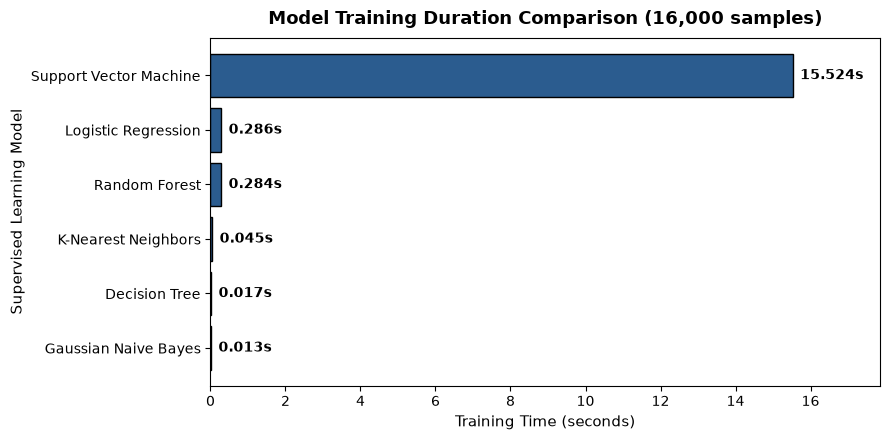

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 4.5))
bars = plt.barh(time_df["Model"], time_df["Training Time (s)"], color="#2b5c8f", edgecolor="black")
plt.title("Model Training Duration Comparison (10,320 samples)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Training Time (seconds)", fontsize=11)
plt.ylabel("Supervised Learning Model", fontsize=11)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.2, bar.get_y() + bar.get_height() / 2, f"{w:.3f}s", va='center', fontweight='bold', fontsize=10)

plt.xlim(0, max(time_df["Training Time (s)"]) * 1.15)
plt.tight_layout()
plt.show()


## 5. Summary
- All 6 classifiers trained smoothly on 10,320 samples.
- Tree-based methods (Decision Tree, Random Forest) trained in under 0.5 seconds.
- SVM required the longest training time (~16s) due to kernel distance calculations.
